In [1]:
# ============================================================
# Temporal EDA - Imports
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# ============================================================
# Load Temporal Market Value Dataset
# ============================================================

DATA_PATH = (
    '../../../data/processed/'
    'temporal_market_value_dataset.csv'
)

df = pd.read_csv(
    DATA_PATH,
    parse_dates=[
        'snapshot_date',
        'target_date',
        'future_date',
        'performance_window_start'
    ]
)

print("=" * 70)
print("TEMPORAL DATASET LOADED")
print("=" * 70)

print(f"Rows    : {len(df):,}")
print(f"Columns : {df.shape[1]}")
print(f"Players : {df['player_id'].nunique():,}")

print("\nSnapshot range:")
print(
    df['snapshot_date'].min(),
    "→",
    df['snapshot_date'].max()
)

print("\nFuture target range:")
print(
    df['future_date'].min(),
    "→",
    df['future_date'].max()
)

TEMPORAL DATASET LOADED
Rows    : 213,905
Columns : 26
Players : 24,275

Snapshot range:
2012-07-06 00:00:00 → 2025-12-22 00:00:00

Future target range:
2012-12-29 00:00:00 → 2026-05-18 00:00:00


In [3]:
# ============================================================
# Dataset Structure
# ============================================================

print("=" * 70)
print("TEMPORAL DATASET STRUCTURE")
print("=" * 70)

print("\nData types:")
display(df.dtypes.to_frame('dtype'))

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")

missing_summary = pd.DataFrame({
    'Missing_Count': df.isna().sum(),
    'Missing_Percent': (
        df.isna().sum()
        / len(df)
        * 100
    )
})

display(
    missing_summary[
        missing_summary['Missing_Count'] > 0
    ].sort_values(
        'Missing_Percent',
        ascending=False
    )
)

TEMPORAL DATASET STRUCTURE

Data types:


,dtype
player_id,int64
snapshot_date,datetime64[ns]
target_date,datetime64[ns]
future_date,datetime64[ns]
target_distance_days,int64
performance_window_start,datetime64[ns]
current_market_value,int64
age_at_snapshot,float64
games_last_6m,float64
goals_last_6m,float64



First 5 rows:


,player_id,snapshot_date,target_date,future_date,target_distance_days,performance_window_start,current_market_value,age_at_snapshot,games_last_6m,goals_last_6m,assists_last_6m,minutes_last_6m,yellow_cards_last_6m,red_cards_last_6m,goals_per_90_last_6m,assists_per_90_last_6m,goal_contribution_per_90_last_6m,minutes_per_game_last_6m,height_in_cm,position,sub_position,foot,country_of_citizenship,future_market_value,future_value_change_eur,future_value_change_pct
0,4520,2012-07-06,2013-01-06,2013-01-12,6,2012-01-06,2500000,32.63,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,181.00,Defender,Centre-Back,right,Netherlands,2000000,-500000,-20.00
1,30003,2012-07-06,2013-01-06,2013-01-12,6,2012-01-06,5000000,25.88,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,176.00,Midfield,Defensive Midfield,right,NaN,4500000,-500000,-10.00
2,47740,2012-07-06,2013-01-06,2013-01-17,11,2012-01-06,400000,20.40,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,190.00,Defender,Centre-Back,both,Germany,600000,200000,50.00
3,60312,2012-07-06,2013-01-06,2013-01-17,11,2012-01-06,600000,23.76,1.00,1.00,1.00,45.00,0.00,0.00,NaN,NaN,NaN,45.00,175.00,Attack,Left Winger,right,Aruba,1250000,650000,108.33
4,80073,2012-07-06,2013-01-06,2013-01-09,3,2012-01-06,1500000,25.43,1.00,2.00,1.00,90.00,0.00,0.00,2.00,1.00,3.00,90.00,194.00,Attack,Centre-Forward,right,Netherlands,2000000,500000,33.33



Missing values:


,Missing_Count,Missing_Percent
goals_per_90_last_6m,92222,43.11
goal_contribution_per_90_last_6m,92222,43.11
assists_per_90_last_6m,92222,43.11
minutes_per_game_last_6m,79865,37.34
foot,3030,1.42
height_in_cm,2052,0.96
country_of_citizenship,1531,0.72
sub_position,214,0.10
age_at_snapshot,203,0.09


FUTURE MARKET VALUE DISTRIBUTION
count       213,905.00
mean      3,905,672.07
std       9,595,893.33
min          10,000.00
25%         350,000.00
50%         800,000.00
75%       3,000,000.00
max     200,000,000.00
Name: future_market_value, dtype: float64

Median:
€800,000

Mean:
€3,905,672


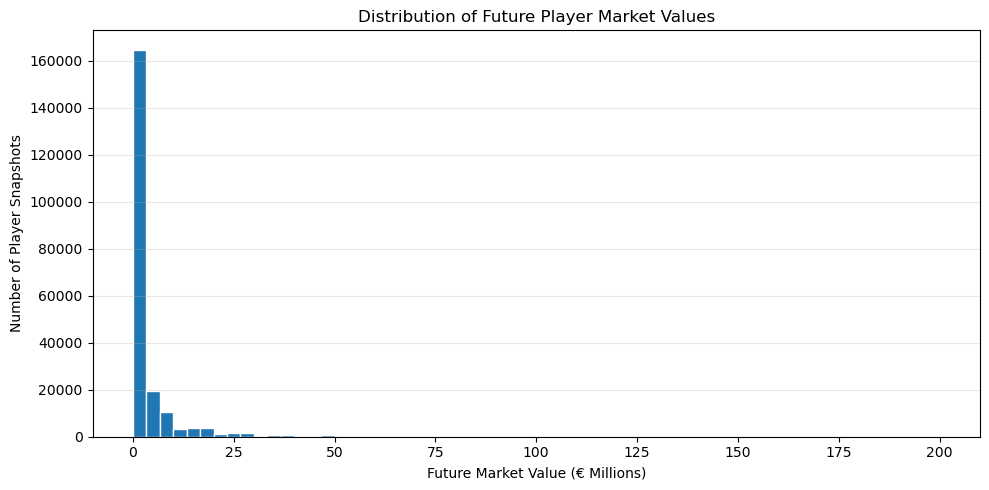

In [4]:
# ============================================================
# Future Market Value - Target Distribution
# ============================================================

target = df['future_market_value']

print("=" * 70)
print("FUTURE MARKET VALUE DISTRIBUTION")
print("=" * 70)

print(target.describe())

print("\nMedian:")
print(f"€{target.median():,.0f}")

print("\nMean:")
print(f"€{target.mean():,.0f}")

plt.figure(figsize=(10, 5))

plt.hist(
    target / 1_000_000,
    bins=60,
    edgecolor='white'
)

plt.xlabel('Future Market Value (€ Millions)')
plt.ylabel('Number of Player Snapshots')

plt.title(
    'Distribution of Future Player Market Values'
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

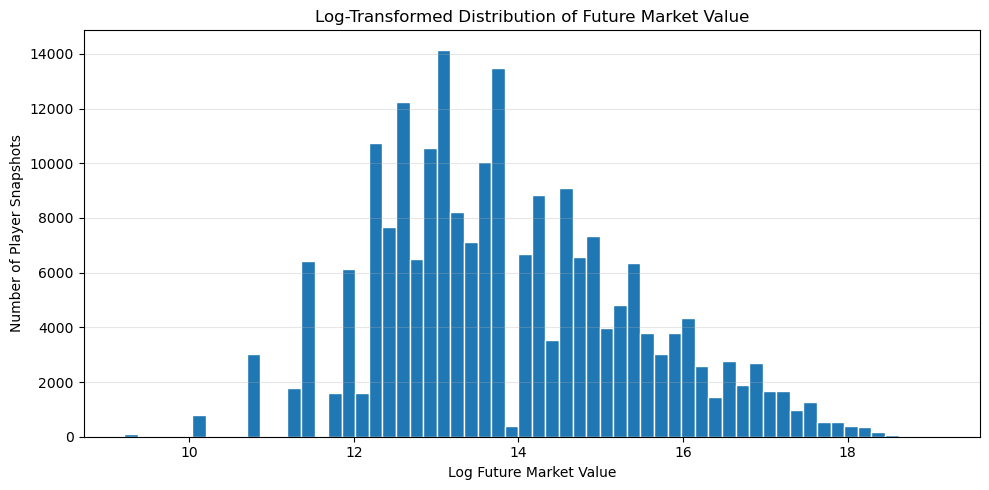

In [5]:
# ============================================================
# Log Future Market Value Distribution
# ============================================================

log_future_value = np.log1p(
    df['future_market_value']
)

plt.figure(figsize=(10, 5))

plt.hist(
    log_future_value,
    bins=60,
    edgecolor='white'
)

plt.xlabel('Log Future Market Value')
plt.ylabel('Number of Player Snapshots')

plt.title(
    'Log-Transformed Distribution of Future Market Value'
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

CURRENT VS FUTURE MARKET VALUE
Pearson correlation : 0.9596


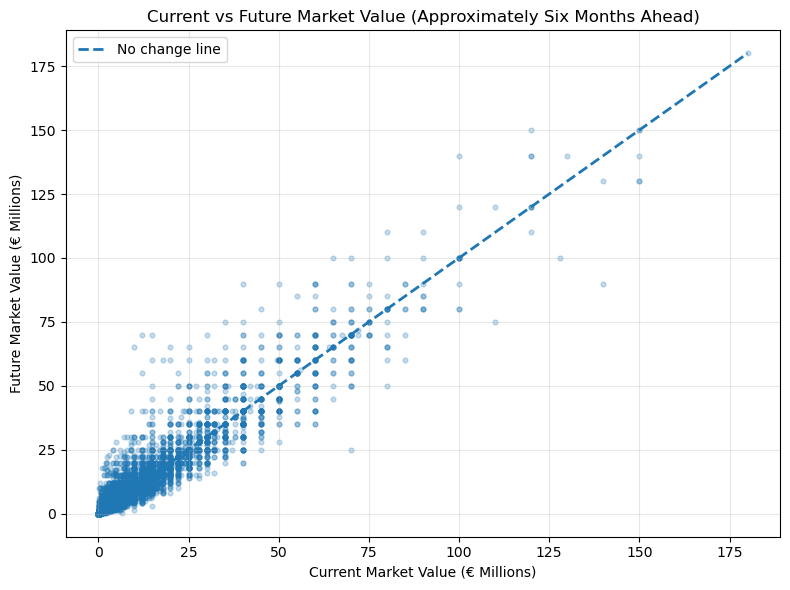

In [6]:
# ============================================================
# Current vs Future Market Value
# ============================================================

current_future_corr = df[
    [
        'current_market_value',
        'future_market_value'
    ]
].corr().iloc[0, 1]

print("=" * 70)
print("CURRENT VS FUTURE MARKET VALUE")
print("=" * 70)

print(
    f"Pearson correlation : "
    f"{current_future_corr:.4f}"
)

# Sample only for clearer/faster visualization
plot_sample = df.sample(
    n=min(30000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 6))

plt.scatter(
    plot_sample['current_market_value'] / 1_000_000,
    plot_sample['future_market_value'] / 1_000_000,
    alpha=0.25,
    s=12
)

max_value = max(
    plot_sample['current_market_value'].max(),
    plot_sample['future_market_value'].max()
) / 1_000_000

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle='--',
    linewidth=2,
    label='No change line'
)

plt.xlabel('Current Market Value (€ Millions)')
plt.ylabel('Future Market Value (€ Millions)')

plt.title(
    'Current vs Future Market Value '
    '(Approximately Six Months Ahead)'
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

LOG CURRENT VS LOG FUTURE MARKET VALUE
Log-scale Pearson correlation : 0.9668


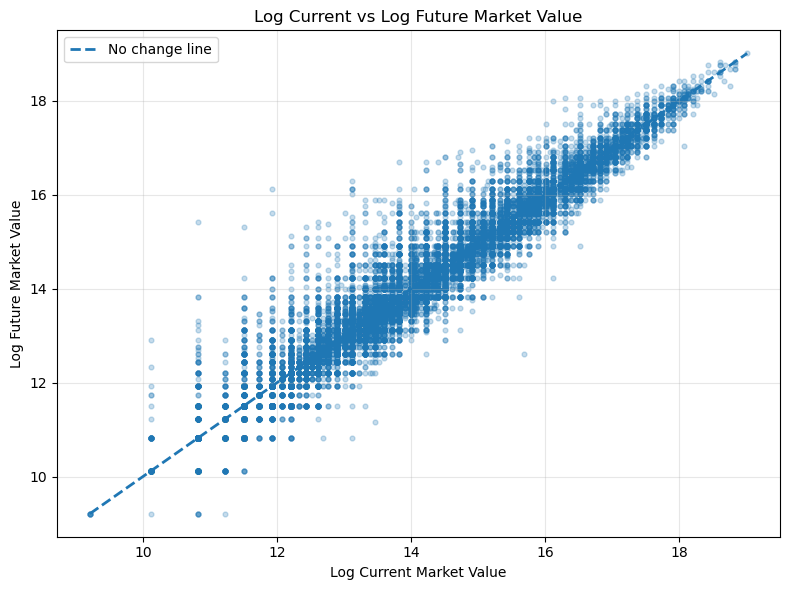

In [7]:
# ============================================================
# Log Current vs Log Future Market Value
# ============================================================

log_current = np.log1p(
    df['current_market_value']
)

log_future = np.log1p(
    df['future_market_value']
)

log_corr = np.corrcoef(
    log_current,
    log_future
)[0, 1]

print("=" * 70)
print("LOG CURRENT VS LOG FUTURE MARKET VALUE")
print("=" * 70)

print(
    f"Log-scale Pearson correlation : "
    f"{log_corr:.4f}"
)

plot_sample = plot_sample.copy()

plot_sample['log_current_value'] = np.log1p(
    plot_sample['current_market_value']
)

plot_sample['log_future_value'] = np.log1p(
    plot_sample['future_market_value']
)

plt.figure(figsize=(8, 6))

plt.scatter(
    plot_sample['log_current_value'],
    plot_sample['log_future_value'],
    alpha=0.25,
    s=12
)

min_log = min(
    plot_sample['log_current_value'].min(),
    plot_sample['log_future_value'].min()
)

max_log = max(
    plot_sample['log_current_value'].max(),
    plot_sample['log_future_value'].max()
)

plt.plot(
    [min_log, max_log],
    [min_log, max_log],
    linestyle='--',
    linewidth=2,
    label='No change line'
)

plt.xlabel('Log Current Market Value')
plt.ylabel('Log Future Market Value')

plt.title(
    'Log Current vs Log Future Market Value'
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

FUTURE MARKET VALUE CHANGE DIRECTION


,Count,Percent
value_direction,,
Decrease,89490,41.84
No Change,64429,30.12
Increase,59986,28.04


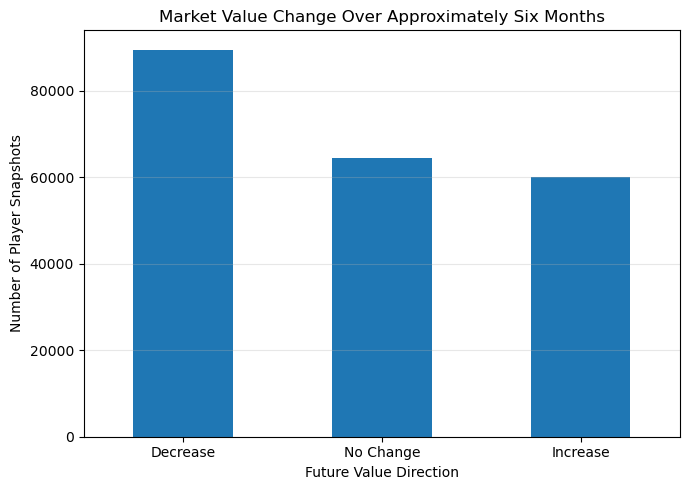

In [8]:
# ============================================================
# Future Market Value Change Direction
# ============================================================

df['value_direction'] = np.select(
    [
        df['future_market_value']
        > df['current_market_value'],

        df['future_market_value']
        < df['current_market_value']
    ],
    [
        'Increase',
        'Decrease'
    ],
    default='No Change'
)

direction_summary = (
    df['value_direction']
    .value_counts()
    .to_frame('Count')
)

direction_summary['Percent'] = (
    direction_summary['Count']
    / len(df)
    * 100
)

print("=" * 70)
print("FUTURE MARKET VALUE CHANGE DIRECTION")
print("=" * 70)

display(direction_summary)

plt.figure(figsize=(7, 5))

direction_summary['Count'].plot(
    kind='bar'
)

plt.xlabel('Future Value Direction')
plt.ylabel('Number of Player Snapshots')

plt.title(
    'Market Value Change Over '
    'Approximately Six Months'
)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

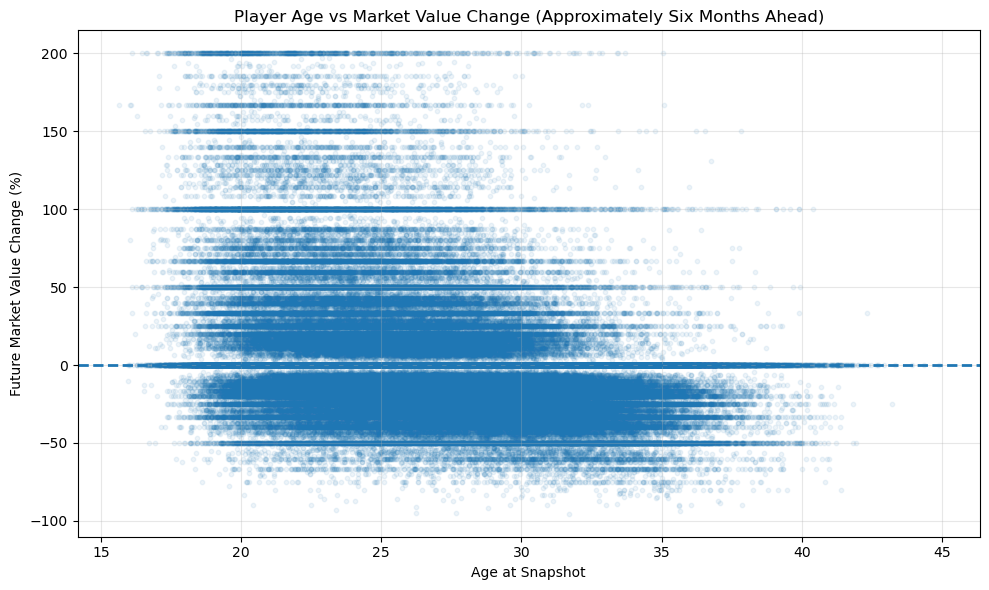

In [9]:
# ============================================================
# Market Value Change by Age
# ============================================================

df['future_value_change_pct'] = (
    (
        df['future_market_value']
        - df['current_market_value']
    )
    / df['current_market_value']
    * 100
)

age_analysis = df[
    [
        'age_at_snapshot',
        'future_value_change_pct'
    ]
].dropna().copy()

# Limit only for visualization to reduce extreme percentage outliers
age_plot = age_analysis[
    age_analysis['future_value_change_pct'].between(-100, 200)
]

plt.figure(figsize=(10, 6))

plt.scatter(
    age_plot['age_at_snapshot'],
    age_plot['future_value_change_pct'],
    alpha=0.08,
    s=10
)

plt.axhline(
    0,
    linestyle='--',
    linewidth=2
)

plt.xlabel('Age at Snapshot')
plt.ylabel('Future Market Value Change (%)')

plt.title(
    'Player Age vs Market Value Change '
    '(Approximately Six Months Ahead)'
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

MARKET VALUE CHANGE BY AGE GROUP


,age_group,Snapshots,Median_Current_Value,Median_Future_Value,Median_Change_Pct
0,15-19,10751,"500,000.00","800,000.00",16.67
1,20-22,37895,"800,000.00","1,000,000.00",0.00
2,23-25,50384,"1,000,000.00","1,200,000.00",0.00
3,26-28,48750,"1,200,000.00","1,000,000.00",0.00
4,29-31,37557,"900,000.00","800,000.00",-12.00
5,32-34,21094,"500,000.00","400,000.00",-16.67
6,35-39,7051,"250,000.00","200,000.00",-10.00
7,40+,220,"100,000.00","100,000.00",0.00


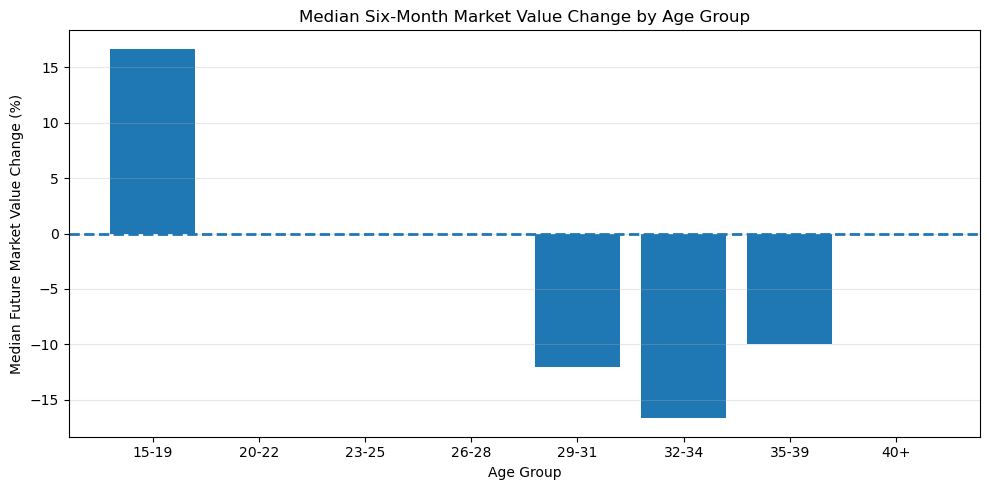

In [10]:
# ============================================================
# Market Value Change by Age Group
# ============================================================

age_bins = [15, 20, 23, 26, 29, 32, 35, 40, 50]

age_labels = [
    '15-19',
    '20-22',
    '23-25',
    '26-28',
    '29-31',
    '32-34',
    '35-39',
    '40+'
]

df['age_group'] = pd.cut(
    df['age_at_snapshot'],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_group_summary = (
    df
    .groupby(
        'age_group',
        observed=True
    )
    .agg(
        Snapshots=('future_market_value', 'size'),
        Median_Current_Value=('current_market_value', 'median'),
        Median_Future_Value=('future_market_value', 'median'),
        Median_Change_Pct=('future_value_change_pct', 'median')
    )
    .reset_index()
)

print("=" * 70)
print("MARKET VALUE CHANGE BY AGE GROUP")
print("=" * 70)

display(age_group_summary)

plt.figure(figsize=(10, 5))

plt.bar(
    age_group_summary['age_group'].astype(str),
    age_group_summary['Median_Change_Pct']
)

plt.axhline(
    0,
    linestyle='--',
    linewidth=2
)

plt.xlabel('Age Group')
plt.ylabel('Median Future Market Value Change (%)')

plt.title(
    'Median Six-Month Market Value Change by Age Group'
)

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# Recent Performance vs Future Market Value Change
# ============================================================

performance_features = [
    'games_last_6m',
    'goals_last_6m',
    'assists_last_6m',
    'minutes_last_6m'
]

performance_change_corr = (
    df[
        performance_features
        + ['future_value_change_pct']
    ]
    .corr()['future_value_change_pct']
    .drop('future_value_change_pct')
    .sort_values(ascending=False)
)

print("=" * 70)
print("RECENT PERFORMANCE VS FUTURE VALUE CHANGE")
print("=" * 70)

print(performance_change_corr)

RECENT PERFORMANCE VS FUTURE VALUE CHANGE
goals_last_6m      0.01
assists_last_6m   -0.00
games_last_6m     -0.01
minutes_last_6m   -0.02
Name: future_value_change_pct, dtype: float64


FUTURE VALUE DIRECTION BY RECENT GOALS


value_direction,Decrease,No Change,Increase
goals_group,,,
0,42.55,31.40,26.05
1-2,41.20,27.48,31.32
3-5,39.46,25.36,35.18
6-10,35.40,24.57,40.03
11+,29.89,26.64,43.47


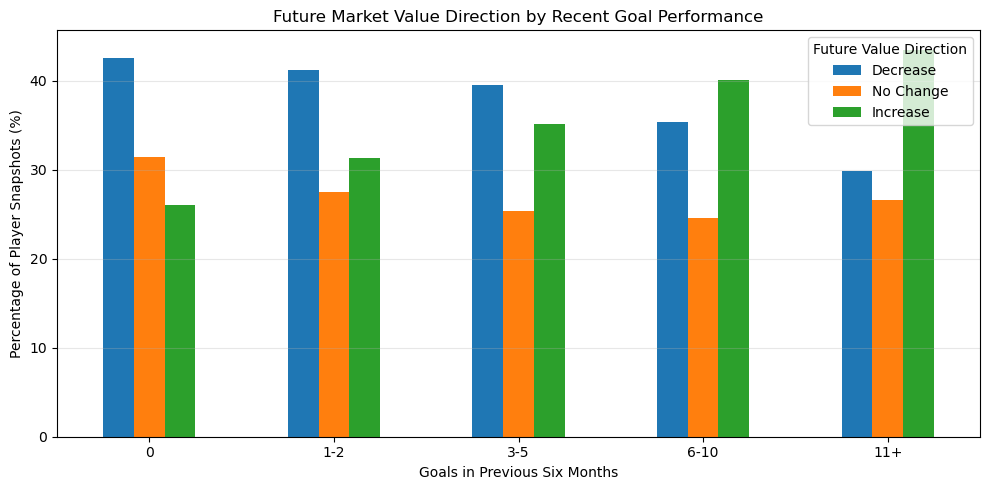

In [14]:
# ============================================================
# Future Value Direction by Recent Goals
# ============================================================

goal_bins = [-1, 0, 2, 5, 10, np.inf]

goal_labels = [
    '0',
    '1-2',
    '3-5',
    '6-10',
    '11+'
]

df['goals_group'] = pd.cut(
    df['goals_last_6m'],
    bins=goal_bins,
    labels=goal_labels
)

goals_direction = (
    pd.crosstab(
        df['goals_group'],
        df['value_direction'],
        normalize='index'
    )
    * 100
)

# Keep consistent column order
direction_order = ['Decrease', 'No Change', 'Increase']

goals_direction = goals_direction.reindex(
    columns=direction_order,
    fill_value=0
)

print("=" * 70)
print("FUTURE VALUE DIRECTION BY RECENT GOALS")
print("=" * 70)

display(goals_direction.round(2))

goals_direction.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Goals in Previous Six Months')
plt.ylabel('Percentage of Player Snapshots (%)')

plt.title(
    'Future Market Value Direction by Recent Goal Performance'
)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.legend(
    title='Future Value Direction'
)

plt.tight_layout()
plt.show()

FUTURE VALUE DIRECTION BY RECENT PLAYING TIME


value_direction,Decrease,No Change,Increase
minutes_group,,,
0,43.17,33.26,23.57
1-450,40.95,29.08,29.97
451-900,45.11,26.36,28.53
901-1350,42.15,27.58,30.27
1351-1800,36.51,29.59,33.90
1800+,34.52,29.62,35.87


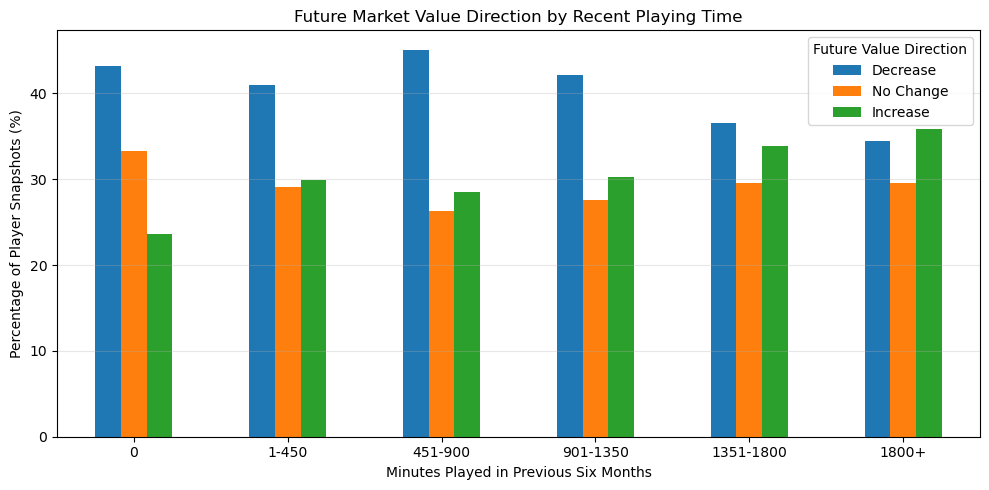

In [15]:
# ============================================================
# Future Value Direction by Recent Playing Time
# ============================================================

minutes_bins = [
    -1,
    0,
    450,
    900,
    1350,
    1800,
    np.inf
]

minutes_labels = [
    '0',
    '1-450',
    '451-900',
    '901-1350',
    '1351-1800',
    '1800+'
]

df['minutes_group'] = pd.cut(
    df['minutes_last_6m'],
    bins=minutes_bins,
    labels=minutes_labels
)

minutes_direction = (
    pd.crosstab(
        df['minutes_group'],
        df['value_direction'],
        normalize='index'
    )
    * 100
)

direction_order = ['Decrease', 'No Change', 'Increase']

minutes_direction = minutes_direction.reindex(
    columns=direction_order,
    fill_value=0
)

print("=" * 70)
print("FUTURE VALUE DIRECTION BY RECENT PLAYING TIME")
print("=" * 70)

display(minutes_direction.round(2))

minutes_direction.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Minutes Played in Previous Six Months')
plt.ylabel('Percentage of Player Snapshots (%)')

plt.title(
    'Future Market Value Direction by Recent Playing Time'
)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.legend(
    title='Future Value Direction'
)

plt.tight_layout()
plt.show()

FUTURE VALUE DIRECTION BY POSITION


,Snapshots,Decrease,No Change,Increase
position,,,,
Defender,70149,40.98,31.11,27.91
Midfield,63728,41.97,29.67,28.36
Attack,61493,43.75,27.07,29.18
Goalkeeper,18321,38.21,38.10,23.69
Missing,214,43.93,33.18,22.90


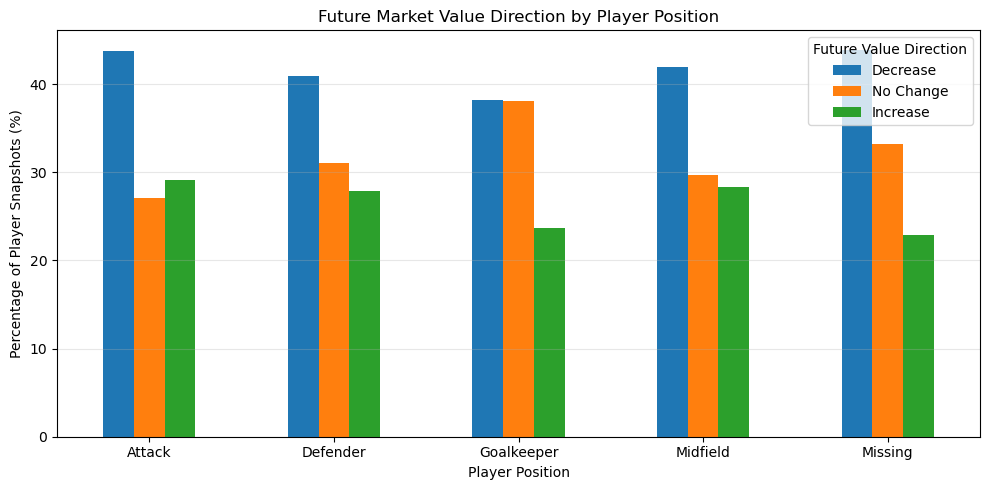

In [16]:
# ============================================================
# Future Value Direction by Position
# ============================================================

position_direction = (
    pd.crosstab(
        df['position'],
        df['value_direction'],
        normalize='index'
    )
    * 100
)

# Keep consistent direction order
direction_order = [
    'Decrease',
    'No Change',
    'Increase'
]

position_direction = position_direction.reindex(
    columns=direction_order,
    fill_value=0
)

# Number of snapshots in each position
position_counts = (
    df['position']
    .value_counts()
    .rename('Snapshots')
)

# Combine counts and percentages
position_summary = (
    position_counts
    .to_frame()
    .join(position_direction)
)

print("=" * 70)
print("FUTURE VALUE DIRECTION BY POSITION")
print("=" * 70)

display(position_summary.round(2))

# Plot
position_direction.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Player Position')
plt.ylabel('Percentage of Player Snapshots (%)')

plt.title(
    'Future Market Value Direction by Player Position'
)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.legend(
    title='Future Value Direction'
)

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# Final Temporal EDA Summary
# ============================================================

print("=" * 75)
print("EXPERIMENT 2 — TEMPORAL EDA SUMMARY")
print("=" * 75)

print(f"""
Dataset:
  Player snapshots        : {len(df):,}
  Unique players          : {df['player_id'].nunique():,}
  Snapshot date range     : {df['snapshot_date'].min().date()} → {df['snapshot_date'].max().date()}

Prediction Task:
  Predict a player's market value approximately six months
  after each historical snapshot.

Target:
  future_market_value

Target Distribution:
  Median future value     : €{df['future_market_value'].median():,.0f}
  Mean future value       : €{df['future_market_value'].mean():,.0f}
  Maximum future value    : €{df['future_market_value'].max():,.0f}

Current vs Future Value:
  Pearson correlation     : {df['current_market_value'].corr(df['future_market_value']):.4f}
  Log-scale correlation   : {np.log1p(df['current_market_value']).corr(np.log1p(df['future_market_value'])):.4f}

Future Value Direction:
  Decrease                : {(df['value_direction'] == 'Decrease').mean() * 100:.2f}%
  No Change               : {(df['value_direction'] == 'No Change').mean() * 100:.2f}%
  Increase                : {(df['value_direction'] == 'Increase').mean() * 100:.2f}%

Key EDA Findings:
  1. Future market value is strongly right-skewed.
  2. Current market value is strongly associated with future market value.
  3. Age shows a clear relationship with subsequent market-value change.
  4. Higher recent goal totals are associated with a greater proportion
     of future market-value increases.
  5. Greater recent playing time, particularly in the highest playing-time
     groups, is associated with a higher proportion of future increases,
     although the relationship is not strictly monotonic.
  6. Future market-value direction differs across player positions.
  7. Individual recent-performance variables show weak linear correlation
     with percentage value change, so nonlinear models and feature
     interactions should still be investigated.

Modelling Implications:
  - Use a temporal train/validation/test split rather than a random split.
  - Keep current_market_value as an important forecasting predictor.
  - Retain age, position and recent six-month performance features.
  - Handle missing values inside the preprocessing pipeline.
  - Compare modelling on the original target and/or log-transformed target.
  - Evaluate predictions using R², MAE and RMSE.
""")

EXPERIMENT 2 — TEMPORAL EDA SUMMARY

Dataset:
  Player snapshots        : 213,905
  Unique players          : 24,275
  Snapshot date range     : 2012-07-06 → 2025-12-22

Prediction Task:
  Predict a player's market value approximately six months
  after each historical snapshot.

Target:
  future_market_value

Target Distribution:
  Median future value     : €800,000
  Mean future value       : €3,905,672
  Maximum future value    : €200,000,000

Current vs Future Value:
  Pearson correlation     : 0.9596
  Log-scale correlation   : 0.9668

Future Value Direction:
  Decrease                : 41.84%
  No Change               : 30.12%
  Increase                : 28.04%

Key EDA Findings:
  1. Future market value is strongly right-skewed.
  2. Current market value is strongly associated with future market value.
  3. Age shows a clear relationship with subsequent market-value change.
  4. Higher recent goal totals are associated with a greater proportion
     of future market-value increa